# Wavelet Image Processing with PyWavelets
This notebook demonstrates how to perform 2D wavelet decomposition on an image using the PyWavelets library (`pywt`). The main steps are:
- Load an image and convert it to grayscale.
- Perform a multi-level (2-level) 2D wavelet decomposition using the Daubechies 1 ('db1') wavelet.
- Normalize the wavelet coefficients for visualization.
- Combine the coefficients into a single array for display.
- Visualize the wavelet decomposition result as an image.
Wavelet decomposition is a powerful tool for analyzing images at multiple scales and extracting both spatial and frequency information.

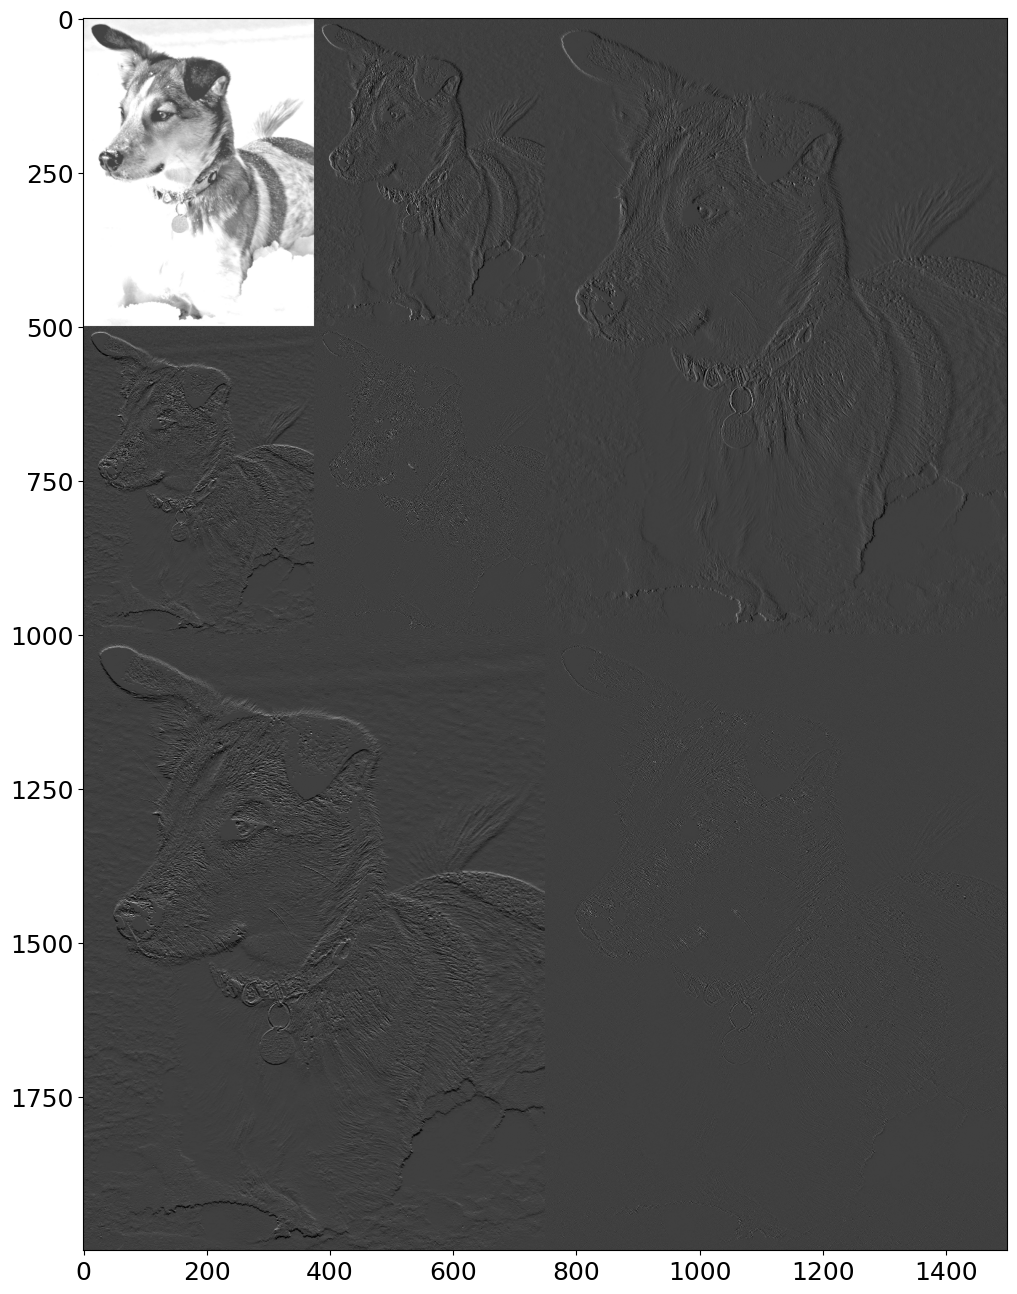

In [2]:
# Using the PyWavelets module, available at 
# https://pywavelets.readthedocs.io/en/latest/install.html

from matplotlib.image import imread
import numpy as np
import matplotlib.pyplot as plt
import os
import pywt
plt.rcParams['figure.figsize'] = [16, 16]
plt.rcParams.update({'font.size': 18})

A = imread(os.path.join('..','DATA','dog.jpg'))
B = np.mean(A, -1); # Convert RGB to grayscale



## Wavelet decomposition (2 level)
n = 2
w = 'db1'
coeffs = pywt.wavedec2(B,wavelet=w,level=n)

# normalize each coefficient array
coeffs[0] /= np.abs(coeffs[0]).max()
for detail_level in range(n):
    coeffs[detail_level + 1] = [d/np.abs(d).max() for d in coeffs[detail_level + 1]]

arr, coeff_slices = pywt.coeffs_to_array(coeffs)



plt.imshow(arr,cmap='gray',vmin=-0.25,vmax=0.75)
plt.show()



### Trying a Different Wavelet: Haar
PyWavelets supports many wavelet types. The Haar wavelet (also called 'haar') is the simplest and one of the most commonly used. Below, we repeat the decomposition using the Haar wavelet and visualize the result for comparison.

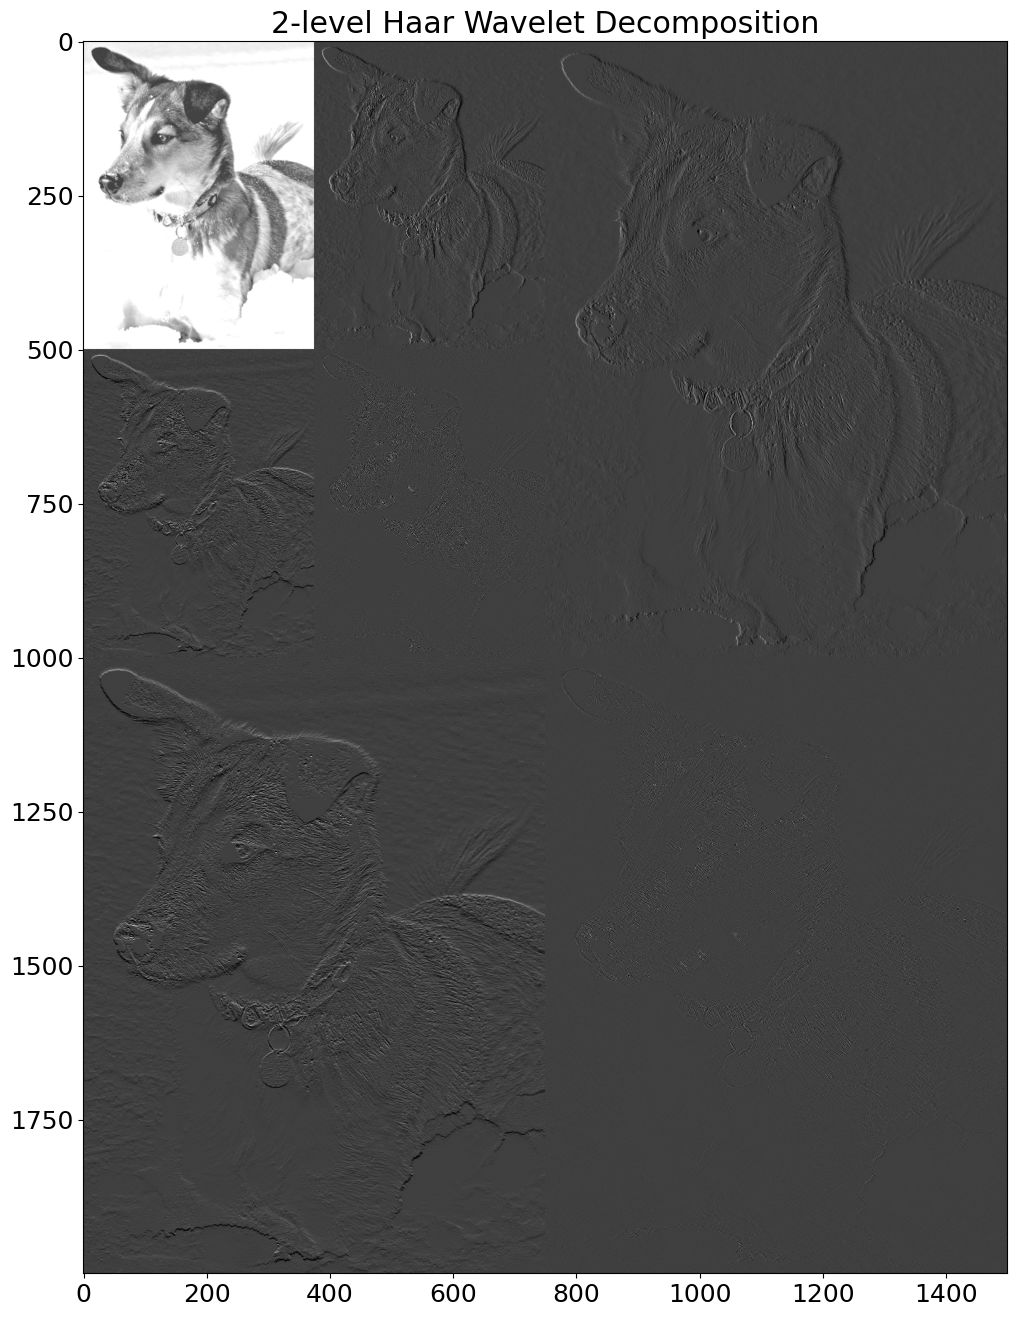

In [3]:
# Wavelet decomposition using Haar wavelet
n = 2
w = 'haar'  # Haar wavelet
coeffs_haar = pywt.wavedec2(B, wavelet=w, level=n)
# normalize each coefficient array
coeffs_haar[0] /= np.abs(coeffs_haar[0]).max()
for detail_level in range(n):
    coeffs_haar[detail_level + 1] = [d/np.abs(d).max() for d in coeffs_haar[detail_level + 1]]
arr_haar, coeff_slices_haar = pywt.coeffs_to_array(coeffs_haar)
plt.imshow(arr_haar, cmap='gray', vmin=-0.25, vmax=0.75)
plt.title('2-level Haar Wavelet Decomposition')
plt.show()

### What does the wavelet decomposition plot show?
The plot visualizes the 2D wavelet decomposition of the grayscale image:

- The large block in the top-left corner represents the approximation (low-frequency) coefficients at the coarsest scale, capturing the overall structure of the image.
- The other blocks (to the right and below) represent detail coefficients at different scales and orientations (horizontal, vertical, diagonal), highlighting edges, textures, and fine details.
- Brighter and darker regions correspond to stronger positive or negative wavelet coefficients, indicating significant features or transitions in the image at various scales.
In summary, the plot provides a compact, multi-scale summary of the image’s structure and details, as extracted by the wavelet transform.